# TRUSTSR Lab 11 — Recovery Verification Engine
**Version:** 1.0.0 | **Evidence class:** Synthetic simulation | **Status:** Executable prototype

## Objective
Implement a recovery-verification gate that produces a final **PASS** or **FAIL** only after evaluating four independent checks:

1. **Checkpoint Valid?** — checkpoint metadata, integrity digest, and trusted provenance match the expected values.
2. **Audit Valid?** — required audit events exist, are ordered, and are linked to the same recovery transaction.
3. **Recovery Completed?** — the recovery workflow reports completion and the expected target version is present.
4. **Contamination Removed?** — every known contaminated artifact in the synthetic ground-truth set is absent from the recovered state, and no unverified artifact is silently accepted.

**Decision rule:** `PASS` only if all four checks pass. Any failed or indeterminate check produces `FAIL` (fail-closed). The final decision is a policy result over synthetic inputs—not a security guarantee.

## Scope and limitations
This lab uses synthetic records and a deterministic verifier. It does not validate real cryptographic key management, production checkpoint storage, tamper-proof logging, or an actual agent runtime. A passing result means only that the simulated evidence satisfies the implemented rules.

## 1. Imports and synthetic scenario

In [1]:
from pathlib import Path
from copy import deepcopy
import hashlib
import json
import pandas as pd
import matplotlib.pyplot as plt
from datetime import datetime, timezone

RUN_UTC = datetime.now(timezone.utc).isoformat()
TX_ID = "SYNTH-RECOVERY-TX-001"
EXPECTED_TARGET_VERSION = "agent-state-v7"

# Synthetic artifacts: a0 is known contaminated; a1/a2 are expected clean.
GROUND_TRUTH = {
    "known_contaminated_artifacts": {"a0"},
    "expected_clean_artifacts": {"a1", "a2"},
    "target_version": EXPECTED_TARGET_VERSION,
}
print("Run UTC:", RUN_UTC)
print("Evidence class: synthetic simulation")
print("Known contaminated artifacts:", sorted(GROUND_TRUTH["known_contaminated_artifacts"]))

Run UTC: 2026-10-11T10:27:44.825125+00:00
Evidence class: synthetic simulation
Known contaminated artifacts: ['a0']


## 2. Create checkpoint, audit, and recovery evidence

In [2]:
def canonical_digest(payload):
    encoded = json.dumps(payload, sort_keys=True, separators=(",", ":")).encode("utf-8")
    return hashlib.sha256(encoded).hexdigest()

checkpoint_payload = {
    "checkpoint_id": "CKPT-SYNTH-042",
    "transaction_id": TX_ID,
    "provenance": "trusted-synthetic-source",
    "version": "agent-state-v6",
    "artifacts": ["a1", "a2"],
    "contaminated_artifacts": [],
}
checkpoint = {
    "payload": checkpoint_payload,
    "sha256": canonical_digest(checkpoint_payload),
    "expected_sha256": canonical_digest(checkpoint_payload),
    "signature_valid": True,  # Synthetic flag; no real signature verification occurs.
    "provenance_trusted": True,
}

audit_events = [
    {"transaction_id": TX_ID, "seq": 1, "event": "recovery_started", "checkpoint_id": "CKPT-SYNTH-042"},
    {"transaction_id": TX_ID, "seq": 2, "event": "checkpoint_restored", "checkpoint_id": "CKPT-SYNTH-042"},
    {"transaction_id": TX_ID, "seq": 3, "event": "verification_requested", "checkpoint_id": "CKPT-SYNTH-042"},
]
recovery_record = {
    "transaction_id": TX_ID,
    "completed": True,
    "target_version": EXPECTED_TARGET_VERSION,
    "restored_artifacts": ["a1", "a2"],
    "unverified_artifacts": [],
}
print("Synthetic checkpoint digest:", checkpoint["sha256"])
print("Audit events:", len(audit_events))
print("Recovery record prepared.")

Synthetic checkpoint digest: 5af867d4149ad1a7dca48e8ac3329f7ad687e63edc504b1da328bc26579a97cb
Audit events: 3
Recovery record prepared.


## 3. Define the four verification gates

In [3]:
REQUIRED_AUDIT_EVENTS = [
    "recovery_started",
    "checkpoint_restored",
    "verification_requested",
]

def verify_checkpoint(cp, transaction_id):
    payload = cp.get("payload")
    if not isinstance(payload, dict):
        return False, "missing_or_invalid_payload"
    digest = canonical_digest(payload)
    checks = {
        "digest_matches": digest == cp.get("sha256") == cp.get("expected_sha256"),
        "transaction_matches": payload.get("transaction_id") == transaction_id,
        "provenance_trusted": cp.get("provenance_trusted") is True,
        "signature_flag_valid": cp.get("signature_valid") is True,
    }
    ok = all(checks.values())
    return ok, "all_checkpoint_checks_passed" if ok else "checkpoint_check_failed:" + ",".join(k for k,v in checks.items() if not v)

def verify_audit(events, transaction_id, checkpoint_id):
    if not isinstance(events, list) or not events:
        return False, "audit_missing"
    relevant = [e for e in events if e.get("transaction_id") == transaction_id]
    seqs = [e.get("seq") for e in relevant]
    names = [e.get("event") for e in relevant]
    same_checkpoint = all(e.get("checkpoint_id") == checkpoint_id for e in relevant)
    ordered_unique = all(isinstance(s, int) for s in seqs) and seqs == sorted(seqs) and len(seqs) == len(set(seqs))
    required_present = all(name in names for name in REQUIRED_AUDIT_EVENTS)
    if not (relevant and same_checkpoint and ordered_unique and required_present):
        return False, "audit_check_failed"
    return True, "required_audit_events_present_ordered_and_correlated"

def verify_recovery(record, transaction_id, expected_version):
    checks = (
        record.get("transaction_id") == transaction_id
        and record.get("completed") is True
        and record.get("target_version") == expected_version
    )
    return (True, "recovery_completed_at_expected_version") if checks else (False, "recovery_incomplete_or_version_mismatch")

def verify_contamination(record, ground_truth):
    restored = set(record.get("restored_artifacts", []))
    unverified = set(record.get("unverified_artifacts", []))
    known_contaminated = set(ground_truth["known_contaminated_artifacts"])
    expected_clean = set(ground_truth["expected_clean_artifacts"])
    contaminated_present = restored & known_contaminated
    missing_expected_clean = expected_clean - restored
    if contaminated_present or unverified or missing_expected_clean:
        return False, {
            "contaminated_artifacts_present": sorted(contaminated_present),
            "unverified_artifacts": sorted(unverified),
            "missing_expected_clean_artifacts": sorted(missing_expected_clean),
        }
    return True, {
        "contaminated_artifacts_present": [],
        "unverified_artifacts": [],
        "missing_expected_clean_artifacts": [],
    }

def run_verification(cp, events, recovery, ground_truth):
    checkpoint_ok, checkpoint_reason = verify_checkpoint(cp, TX_ID)
    audit_ok, audit_reason = verify_audit(events, TX_ID, cp.get("payload", {}).get("checkpoint_id"))
    recovery_ok, recovery_reason = verify_recovery(recovery, TX_ID, ground_truth["target_version"])
    contamination_ok, contamination_details = verify_contamination(recovery, ground_truth)
    checks = [
        ("Checkpoint Valid?", checkpoint_ok, checkpoint_reason),
        ("Audit Valid?", audit_ok, audit_reason),
        ("Recovery Completed?", recovery_ok, recovery_reason),
        ("Contamination Removed?", contamination_ok, json.dumps(contamination_details, sort_keys=True)),
    ]
    final_status = "PASS" if all(ok for _, ok, _ in checks) else "FAIL"
    results = pd.DataFrame([
        {"check":name, "status":"PASS" if ok else "FAIL", "passed":bool(ok), "details":reason}
        for name, ok, reason in checks
    ])
    return final_status, results

print("Verification gates defined.")

Verification gates defined.


## 4. Run the nominal recovery case

In [4]:
nominal_status, nominal_results = run_verification(
    checkpoint, audit_events, recovery_record, GROUND_TRUTH
)
display(nominal_results)
print("FINAL RECOVERY VERDICT:", nominal_status)
assert nominal_status == "PASS"
assert nominal_results["passed"].all()
print("Nominal-case assertions passed (synthetic evidence only).")

                    check status  passed                                                                details
0       Checkpoint Valid?   PASS    True                                           all_checkpoint_checks_passed
1            Audit Valid?   PASS    True                   required_audit_events_present_ordered_and_correlated
2     Recovery Completed?   PASS    True                                 recovery_completed_at_expected_version
3  Contamination Removed?   PASS    True  {"contaminated_artifacts_present": [], "missing_expected_clean_art...

FINAL RECOVERY VERDICT: PASS
Nominal-case assertions passed (synthetic evidence only).


## 5. Fault injection: prove each gate can fail independently

In [5]:
def evaluate_fault(name, cp=None, events=None, recovery=None, truth=None, expected_failed_check=None):
    cp = deepcopy(checkpoint if cp is None else cp)
    events = deepcopy(audit_events if events is None else events)
    recovery = deepcopy(recovery_record if recovery is None else recovery)
    truth = deepcopy(GROUND_TRUTH if truth is None else truth)
    status, results = run_verification(cp, events, recovery, truth)
    failed = set(results.loc[~results["passed"], "check"])
    assert status == ("PASS" if not failed else "FAIL")
    if expected_failed_check:
        assert expected_failed_check in failed, f"{name}: expected {expected_failed_check} to fail, got {failed}"
    return {
        "fault_case":name,
        "final_verdict":status,
        "failed_checks":"|".join(sorted(failed)),
        "passed_check_count":int(results["passed"].sum()),
        "failed_check_count":int((~results["passed"]).sum()),
        "evidence_classification":"synthetic fault injection",
    }, results

fault_rows = []
fault_detail_rows = []

# 1. Checkpoint payload tampering without digest update.
bad_cp = deepcopy(checkpoint)
bad_cp["payload"]["version"] = "tampered-version"
row, detail = evaluate_fault("checkpoint_payload_tampering", cp=bad_cp,
    expected_failed_check="Checkpoint Valid?")
fault_rows.append(row); fault_detail_rows.extend([{"fault_case":row["fault_case"], **r} for r in detail.to_dict("records")])

# 2. Missing required audit event.
bad_audit = [e for e in deepcopy(audit_events) if e["event"] != "checkpoint_restored"]
row, detail = evaluate_fault("missing_audit_event", events=bad_audit,
    expected_failed_check="Audit Valid?")
fault_rows.append(row); fault_detail_rows.extend([{"fault_case":row["fault_case"], **r} for r in detail.to_dict("records")])

# 3. Recovery did not complete.
bad_recovery = deepcopy(recovery_record); bad_recovery["completed"] = False
row, detail = evaluate_fault("recovery_incomplete", recovery=bad_recovery,
    expected_failed_check="Recovery Completed?")
fault_rows.append(row); fault_detail_rows.extend([{"fault_case":row["fault_case"], **r} for r in detail.to_dict("records")])

# 4. Known contaminated artifact remains.
bad_contamination = deepcopy(recovery_record); bad_contamination["restored_artifacts"].append("a0")
row, detail = evaluate_fault("contamination_remains", recovery=bad_contamination,
    expected_failed_check="Contamination Removed?")
fault_rows.append(row); fault_detail_rows.extend([{"fault_case":row["fault_case"], **r} for r in detail.to_dict("records")])

fault_df = pd.DataFrame(fault_rows)
fault_details_df = pd.DataFrame(fault_detail_rows)
display(fault_df)
assert fault_df["final_verdict"].eq("FAIL").all()
assert fault_df["failed_check_count"].ge(1).all()
print("All four targeted fault-injection assertions passed.")

                     fault_case final_verdict           failed_checks  passed_check_count  failed_check_count    evidence_classification
0  checkpoint_payload_tampering          FAIL       Checkpoint Valid?                   3                   1  synthetic fault injection
1           missing_audit_event          FAIL            Audit Valid?                   3                   1  synthetic fault injection
2           recovery_incomplete          FAIL     Recovery Completed?                   3                   1  synthetic fault injection
3         contamination_remains          FAIL  Contamination Removed?                   3                   1  synthetic fault injection

All four targeted fault-injection assertions passed.


## 6. Combined faults and fail-closed decision

In [6]:
combined_cp = deepcopy(checkpoint)
combined_cp["payload"]["provenance"] = "untrusted-source"
combined_audit = deepcopy(audit_events)[:1]
combined_recovery = deepcopy(recovery_record)
combined_recovery["completed"] = False
combined_recovery["restored_artifacts"].append("a0")
combined_recovery["unverified_artifacts"] = ["a9"]

combined_status, combined_results = run_verification(
    combined_cp, combined_audit, combined_recovery, GROUND_TRUTH
)
display(combined_results)
print("Combined-fault verdict:", combined_status)
assert combined_status == "FAIL"
assert (~combined_results["passed"]).sum() >= 3
print("Combined-fault fail-closed assertion passed.")

                    check status  passed                                                                details
0       Checkpoint Valid?   FAIL   False                                 checkpoint_check_failed:digest_matches
1            Audit Valid?   FAIL   False                                                     audit_check_failed
2     Recovery Completed?   FAIL   False                                recovery_incomplete_or_version_mismatch
3  Contamination Removed?   FAIL   False  {"contaminated_artifacts_present": ["a0"], "missing_expected_clean...

Combined-fault verdict: FAIL
Combined-fault fail-closed assertion passed.


## 7. Visualize synthetic verification outcomes

                           case final_verdict
0                       nominal          PASS
0  checkpoint_payload_tampering          FAIL
1           missing_audit_event          FAIL
2           recovery_incomplete          FAIL
3         contamination_remains          FAIL
0               combined_faults          FAIL

Plot outcomes are synthetic fault-injection results, not real-world performance metrics.


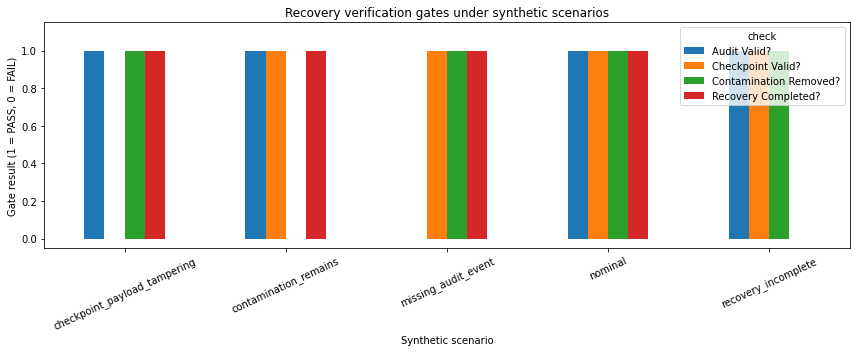

In [7]:
nominal_plot = nominal_results[["check", "passed"]].copy()
nominal_plot["case"] = "nominal"
fault_plot_rows = []
for case_name, group in fault_details_df.groupby("fault_case"):
    for item in group.to_dict("records"):
        fault_plot_rows.append({"case":case_name, "check":item["check"], "passed":item["passed"]})
plot_df = pd.concat([nominal_plot, pd.DataFrame(fault_plot_rows)], ignore_index=True)
pivot = plot_df.pivot_table(index="case", columns="check", values="passed", aggfunc="first", fill_value=False)
ax = pivot.astype(int).plot(kind="bar", figsize=(12,5))
ax.set_title("Recovery verification gates under synthetic scenarios")
ax.set_xlabel("Synthetic scenario")
ax.set_ylabel("Gate result (1 = PASS, 0 = FAIL)")
ax.set_ylim(-0.05, 1.15)
ax.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

verdict_counts = pd.concat([
    pd.DataFrame([{"case":"nominal", "final_verdict":nominal_status}]),
    fault_df[["fault_case","final_verdict"]].rename(columns={"fault_case":"case"}),
    pd.DataFrame([{"case":"combined_faults", "final_verdict":combined_status}]),
])
display(verdict_counts)
print("Plot outcomes are synthetic fault-injection results, not real-world performance metrics.")

## 8. Export reproducibility artifacts

In [8]:
nominal_results.assign(
    scenario="nominal",
    final_verdict=nominal_status,
    evidence_classification="synthetic simulation"
).to_csv("trustsr_lab11_nominal_verification.csv", index=False)

fault_df.to_csv("trustsr_lab11_fault_injection_summary.csv", index=False)
fault_details_df.to_csv("trustsr_lab11_fault_injection_gate_details.csv", index=False)
combined_results = combined_results.assign(
    scenario="combined_faults",
    final_verdict=combined_status,
    evidence_classification="synthetic simulation"
)
combined_results.to_csv("trustsr_lab11_combined_fault_verification.csv", index=False)
verdict_counts.to_csv("trustsr_lab11_verdict_summary.csv", index=False)

exports = [
    "trustsr_lab11_nominal_verification.csv",
    "trustsr_lab11_fault_injection_summary.csv",
    "trustsr_lab11_fault_injection_gate_details.csv",
    "trustsr_lab11_combined_fault_verification.csv",
    "trustsr_lab11_verdict_summary.csv",
]
for filename in exports:
    path = Path(filename)
    assert path.exists() and path.stat().st_size > 0
    print("Created:", filename, "| bytes:", path.stat().st_size)

assert nominal_status == "PASS"
assert fault_df["final_verdict"].eq("FAIL").all()
assert combined_status == "FAIL"
print("FINAL NOTE: all outputs are synthetic; no real recovery system was tested.")

Created: trustsr_lab11_nominal_verification.csv | bytes: 561
Created: trustsr_lab11_fault_injection_summary.csv | bytes: 406
Created: trustsr_lab11_fault_injection_gate_details.csv | bytes: 1790
Created: trustsr_lab11_combined_fault_verification.csv | bytes: 586
Created: trustsr_lab11_verdict_summary.csv | bytes: 164
FINAL NOTE: all outputs are synthetic; no real recovery system was tested.


## 9. Interpretation and publication wording

### What this lab demonstrates
- Four explicit verification gates are evaluated independently.
- The final verdict is `PASS` only when all four gates pass; otherwise it is `FAIL`.
- Four targeted fault-injection cases each trigger the expected gate failure.
- A combined-fault case is rejected by the fail-closed decision rule.
- Per-gate decisions and scenario summaries are exported for review.

### What this lab does not demonstrate
- That the checkpoint signature flag represents real cryptographic verification.
- That audit events are stored in an immutable or authenticated log.
- That the ground-truth contamination set is complete in a real system.
- That an actual agent was recovered, or that real contamination was removed.

### Suggested publication wording
“We implemented a deterministic recovery-verification prototype and tested it on synthetic nominal, single-fault, and combined-fault scenarios. The verifier returned PASS only when checkpoint, audit, completion, and contamination checks all passed. Fault-injection assertions confirmed rejection of the encoded failure cases. These results validate the prototype's behavior on the defined synthetic fixtures only; real-system effectiveness remains untested.”

### Completion checklist
1. Run all cells in a fresh Google Colab runtime.
2. Confirm nominal verdict is `PASS`.
3. Confirm each of the four injected faults returns `FAIL` and fails its expected gate.
4. Confirm the combined-fault case returns `FAIL`.
5. Verify all five CSV exports exist.
6. Preserve the executed notebook and CSVs as the experiment record.